# Module 10 — Deep Learning

**Applied exercises only** · ISLP, Chapter 10

**Printed textbook pages:** 466–467 (exercise starting pages) 

In [1]:
# Common imports: run this cell once before starting the exercises.
# Everything runs in the project's .venv (ISLP, torch, torchvision). Data come from ISLP;
# the IMDb files are downloaded by ISLP into ./data/IMDB on first use.
import json
from glob import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from ISLP import load_data, confusion_table

rng = np.random.default_rng(1)
torch.manual_seed(0)
torch.set_num_threads(4)


def train_torch(model, train_ds, epochs, lr=1e-3, batch_size=64, loss_fn=None, valid=None,
                metric=None, seed=0, weight_decay=0.0):
    """Minimal training loop. Returns per-epoch history of training loss and optional validation metric."""
    torch.manual_seed(seed)
    loss_fn = loss_fn or nn.MSELoss()
    opt = torch.optim.RMSprop(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(yb)
        row = {"epoch": epoch + 1, "train_loss": total / len(train_ds)}
        if valid is not None:
            model.eval()
            with torch.no_grad():
                row["valid"] = metric(model(valid[0]), valid[1])
        history.append(row)
    model.eval()
    return pd.DataFrame(history)

---

## Exercise 6 · Applied

**Textbook: printed page 466**

Consider the simple function R(β) = sin(β) + β/10.

### Exercise 6(a)

Draw a graph of this function over the range β ∈[−6, 6].

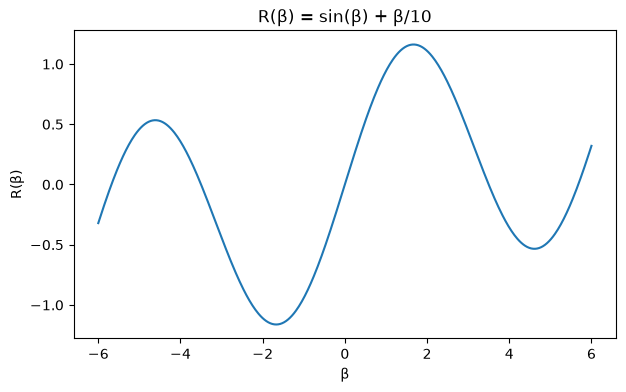

In [2]:
# Exercise 6(a)
R = lambda b: np.sin(b) + b / 10
beta = np.linspace(-6, 6, 500)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(beta, R(beta))
ax.set(xlabel="β", ylabel="R(β)", title="R(β) = sin(β) + β/10")
plt.show()

### Exercise 6(b)

What is the derivative of this function?

In [3]:
# Exercise 6(b)
dR = lambda b: np.cos(b) + 1 / 10
print("dR/dβ = cos(β) + 1/10")

dR/dβ = cos(β) + 1/10


### Exercise 6(c)

Given β0 = 2.3, run gradient descent to find a local minimum
of R(β) using a learning rate of ρ = 0.1. Show each of β0, β1, . . .
in your plot, as well as the final answer.

173 iterations; first steps: [2.3    2.3566 2.4174 2.4823 2.5513 2.6244]
Final β = 4.612221, R(β) = -0.533765


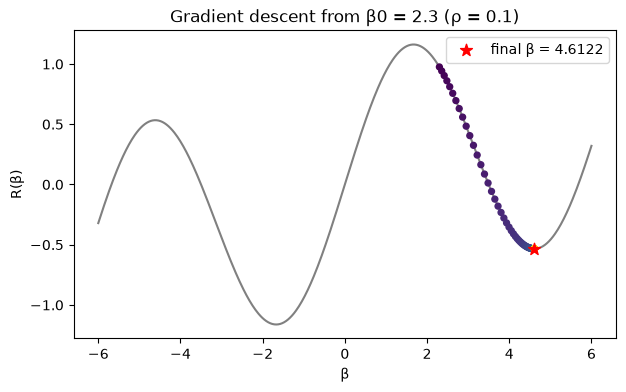

In [4]:
# Exercise 6(c)
def gradient_descent(beta0, rho=0.1, tol=1e-8, max_iter=10_000):
    path = [beta0]
    for _ in range(max_iter):
        step = rho * dR(path[-1])
        path.append(path[-1] - step)
        if abs(step) < tol:
            break
    return np.array(path)

def plot_path(path, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(beta, R(beta), color="gray")
    ax.scatter(path, R(path), c=np.arange(len(path)), cmap="viridis", s=18, zorder=3)
    ax.scatter(path[-1], R(path[-1]), color="red", s=80, marker="*", zorder=4, label=f"final β = {path[-1]:.4f}")
    ax.set(xlabel="β", ylabel="R(β)", title=title)
    ax.legend()
    plt.show()

path_c = gradient_descent(2.3)
print(f"{len(path_c) - 1} iterations; first steps: {path_c[:6].round(4)}")
print(f"Final β = {path_c[-1]:.6f}, R(β) = {R(path_c[-1]):.6f}")
plot_path(path_c, "Gradient descent from β0 = 2.3 (ρ = 0.1)")

### Exercise 6(d)

Repeat with β0 = 1.4.

183 iterations; first steps: [1.4    1.373  1.3434 1.3108 1.2751 1.236 ]
Final β = -1.670964, R(β) = -1.162084


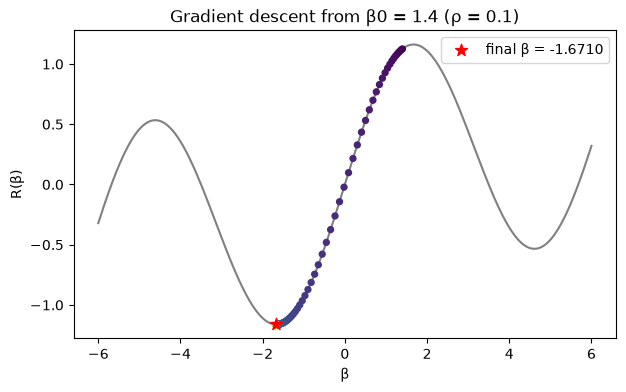

In [5]:
# Exercise 6(d)
path_d = gradient_descent(1.4)
print(f"{len(path_d) - 1} iterations; first steps: {path_d[:6].round(4)}")
print(f"Final β = {path_d[-1]:.6f}, R(β) = {R(path_d[-1]):.6f}")
plot_path(path_d, "Gradient descent from β0 = 1.4 (ρ = 0.1)")

**Observations / conclusions**

- **(b)** $R'(\beta) = \cos\beta + \tfrac{1}{10}$.
- **(c)** From $\beta^0 = 2.3$ with ρ = 0.1, the slope is negative, so gradient descent moves *right*. It converges in ~170 steps to the local minimum **β ≈ 4.612** (where cos β = −0.1), with R ≈ −0.534.
- **(d)** From $\beta^0 = 1.4$ the slope is positive, so it moves *left*. It ends at a different local minimum, **β ≈ −1.671**, with R ≈ −1.162. That one is lower, and is the global minimum on [−6, 6].

Gradient descent only finds a *local* minimum, and which one depends on the starting value. That is why neural-network fits depend on initialisation.

---

## Exercise 7 · Applied

**Textbook: printed page 466**

Fit a neural network to the Default data. Use a single hidden layer
with 10 units, and dropout regularization. Have a look at Labs 10.9.1–
10.9.2 for guidance. Compare the classification performance of your
model with that of linear logistic regression.

In [6]:
# Exercise 7
from sklearn.metrics import roc_auc_score

Default = load_data("Default")
Xd = pd.DataFrame({"balance": Default["balance"], "income": Default["income"],
                   "student": (Default["student"] == "Yes").astype(float)})
yd = (Default["default"] == "Yes").astype(int).to_numpy()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=1/3, random_state=1, stratify=yd)
scaler_d = StandardScaler().fit(Xd_tr)
Xd_tr_s, Xd_te_s = scaler_d.transform(Xd_tr), scaler_d.transform(Xd_te)

# Logistic regression
logit_d = LogisticRegression().fit(Xd_tr_s, yd_tr)
probs_7 = {"Logistic regression": logit_d.predict_proba(Xd_te_s)[:, 1]}

# Neural network: 1 hidden layer with 10 units + dropout. Try a few dropout rates, because with only
# 10 hidden units heavy dropout can make the network too conservative to ever predict a default.
class DefaultNet(nn.Module):
    def __init__(self, p, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(p, 10), nn.ReLU(), nn.Dropout(dropout), nn.Linear(10, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

tr_ds = TensorDataset(torch.tensor(Xd_tr_s, dtype=torch.float32), torch.tensor(yd_tr, dtype=torch.float32))
te_X = torch.tensor(Xd_te_s, dtype=torch.float32)
nets_7 = {}
for rate in [0.1, 0.2, 0.4]:
    torch.manual_seed(0)
    net = DefaultNet(3, rate)
    train_torch(net, tr_ds, epochs=30, lr=1e-2, batch_size=32, loss_fn=nn.BCEWithLogitsLoss())
    with torch.no_grad():
        probs_7[f"Neural net, 10 units, dropout {rate:.0%}"] = torch.sigmoid(net(te_X)).numpy()
    nets_7[rate] = net

rows = []
for name, prob in probs_7.items():
    pred = (prob > 0.5).astype(int)
    rows.append({"model": name, "accuracy": np.mean(pred == yd_te), "AUC": roc_auc_score(yd_te, prob),
                 "predicted defaults": int(pred.sum()), "true defaults caught": int(((pred == 1) & (yd_te == 1)).sum())})
display(pd.DataFrame(rows).set_index("model").round(4))
print(f"Test set: {len(yd_te)} people, {yd_te.sum()} defaults; null classifier accuracy = {1 - yd_te.mean():.4f}")

print("\nConfusion matrix, neural net with 10% dropout:")
display(confusion_table((probs_7["Neural net, 10 units, dropout 10%"] > 0.5).astype(int), yd_te))
print("Confusion matrix, logistic regression:")
display(confusion_table((probs_7["Logistic regression"] > 0.5).astype(int), yd_te))

,accuracy,AUC,predicted defaults,true defaults caught
model,,,,
Logistic regression,0.9757,0.9585,60,45
"Neural net, 10 units, dropout 10%",0.9742,0.9556,37,31
"Neural net, 10 units, dropout 20%",0.9667,0.9571,0,0
"Neural net, 10 units, dropout 40%",0.9667,0.9577,0,0


Test set: 3334 people, 111 defaults; null classifier accuracy = 0.9667

Confusion matrix, neural net with 10% dropout:


Truth,0,1
Predicted,,
0,3217,80
1,6,31


Confusion matrix, logistic regression:


Truth,0,1
Predicted,,
0,3208,66
1,15,45


**Observations / conclusions**

On a stratified 1/3 test set (3,334 people, 111 defaults), using balance, income and student status:

| model | accuracy | AUC | defaults predicted | defaults caught |
|---|---|---|---|---|
| Logistic regression | **0.976** | 0.959 | 60 | 45 |
| NN, 10 hidden units, 10% dropout | 0.974 | 0.956 | 37 | 31 |
| NN, 10 hidden units, 20% / 40% dropout | 0.967 | 0.957 | 0 | 0 |

The neural network gives **no improvement** over logistic regression. The relationship (default probability rising smoothly with balance) is already close to linear on the logit scale, so a hidden layer has nothing extra to find.
Heavier dropout makes the network more conservative. With 20–40% dropout on only 10 units, no predicted probability reaches 0.5, so it predicts "No" for everyone and its accuracy equals the null classifier's 96.7%. Its AUC is unchanged, though, so it still *ranks* customers as well as logistic regression; it would work with a lower threshold. For rare-event problems like this, accuracy at a 0.5 cutoff is a weak measure.

---

## Exercise 8 · Applied

**Textbook: printed page 466**

From your collection of personal photographs, pick 10 images of animals (such as dogs, cats, birds, farm animals, etc.). If the subject
does not occupy a reasonable part of the image, then crop the image.
Now use a pretrained image classification CNN as in Lab 10.9.4 to
predict the class of each of your images, and report the probabilities
for the top five predicted classes for each image.

No images in my_animal_images/ yet, so using the 6 ISLP lab sample images instead.


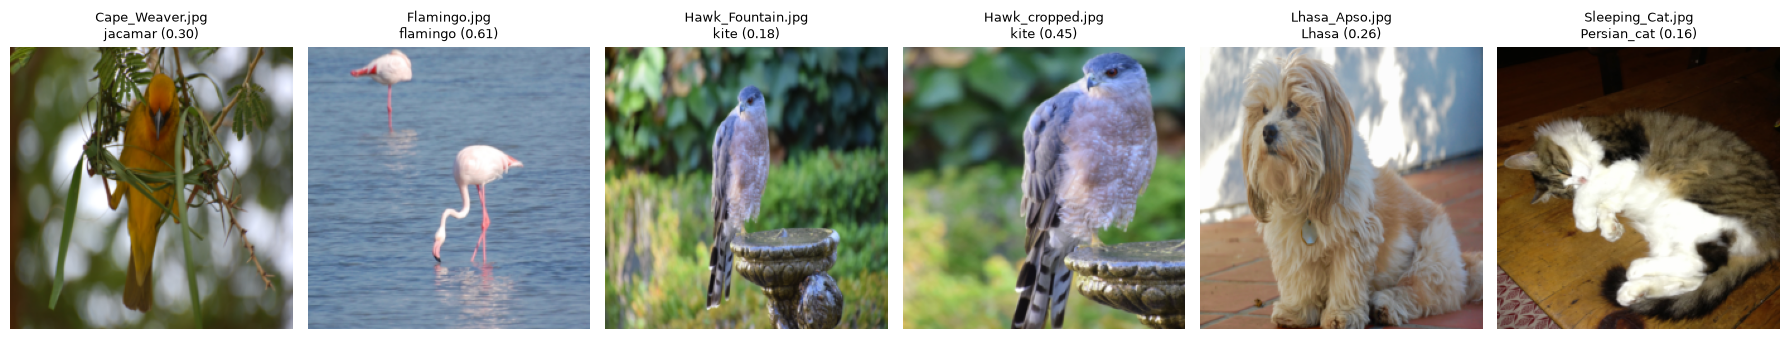


Image: Cape_Weaver.jpg
    label   prob
  jacamar 0.2975
    macaw 0.0681
 lorikeet 0.0511
bee_eater 0.0444
   bulbul 0.0291

Image: Flamingo.jpg
         label   prob
      flamingo 0.6095
     spoonbill 0.0136
American_egret 0.0021
       pelican 0.0014
         crane 0.0013

Image: Hawk_Fountain.jpg
         label   prob
          kite 0.1847
         robin 0.0840
great_grey_owl 0.0613
indigo_bunting 0.0213
      fountain 0.0110

Image: Hawk_cropped.jpg
         label   prob
          kite 0.4538
great_grey_owl 0.0159
           jay 0.0122
         quail 0.0083
         macaw 0.0052

Image: Lhasa_Apso.jpg
          label   prob
          Lhasa 0.2603
       Shih-Tzu 0.0972
Tibetan_terrier 0.0328
 cocker_spaniel 0.0059
       Pekinese 0.0052

Image: Sleeping_Cat.jpg
      label   prob
Persian_cat 0.1631
      tabby 0.0741
  tiger_cat 0.0426
    doormat 0.0345
paper_towel 0.0155


In [7]:
# Exercise 8
# Put your own 10 animal photos in ./my_animal_images/ (jpg/png). Until then, the notebook uses the
# six sample animal photos from the ISLP labs (./book_images/) so the code can be run end to end.
from torchvision.io import decode_image, ImageReadMode
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.transforms import Resize, CenterCrop, Normalize
import ISLP

my_dir = Path("my_animal_images")
imgfiles = sorted(str(f) for f in my_dir.glob("*") if f.suffix.lower() in {".jpg", ".jpeg", ".png"}) if my_dir.exists() else []
if not imgfiles:
    sample_dir = Path("book_images")
    imgfiles = sorted(str(f) for f in sample_dir.glob("*") if f.suffix.lower() in {".jpg", ".jpeg", ".png"})
    print(f"No images in {my_dir}/ yet, so using the {len(imgfiles)} ISLP lab sample images instead.")

resize, crop = Resize((232, 232), antialias=True), CenterCrop(224)
normalize = Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
raw = [crop(resize(decode_image(f, mode=ImageReadMode.RGB))) for f in imgfiles]
imgs = normalize(torch.stack([torch.div(r, 255) for r in raw]))

weights = ResNet50_Weights.DEFAULT
resnet = resnet50(weights=weights).eval()
with torch.no_grad():
    probs = torch.softmax(resnet(imgs), dim=1).numpy()

labels = json.load(open("imagenet_class_index.json"))
class_labels = pd.Series({int(k): v[1] for k, v in labels.items()}).sort_index()

fig, axes = plt.subplots(1, len(imgfiles), figsize=(3 * len(imgfiles), 3.4))
for ax, f, r, pr in zip(np.atleast_1d(axes), imgfiles, raw, probs):
    ax.imshow(r.permute(1, 2, 0).numpy())
    ax.set_title(f"{Path(f).name}\n{class_labels[pr.argmax()]} ({pr.max():.2f})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

for f, pr in zip(imgfiles, probs):
    top5 = np.argsort(pr)[::-1][:5]
    print(f"\nImage: {Path(f).name}")
    print(pd.DataFrame({"label": class_labels[top5].values, "prob": pr[top5].round(4)}).to_string(index=False))

**Observations / conclusions**

*I ran the classifier on the six animal images that come with ISLP. The same code will classify any photos placed in `chapter 10/my_animal_images/`.*

With ResNet-50 (ImageNet weights): the **flamingo** is recognised confidently (p = 0.61). The **hawk** is labelled "kite", which is a bird of prey and a reasonable confusion. Cropping the hawk raises its top probability from 0.18 to 0.45, which shows why the exercise says to crop images. The dog **Huey** is identified as a Lhasa / Shih-Tzu, both small long-haired breeds. **Kitty** comes out as Persian cat / tabby. The **weaver** bird is mislabelled "jacamar" (p = 0.30), because weavers aren't an ImageNet class, so the model picks a visually similar bird. Low top-1 probabilities generally go with ambiguous or out-of-vocabulary subjects.

---

## Exercise 9 · Applied

**Textbook: printed page 466**

Fit a lag-5 autoregressive model to the NYSE data, as described in
the text and Lab 10.9.6. Refit the model with a 12-level factor representing the month. Does this factor improve the performance of the
model?

In [8]:
# Exercise 9
NYSE = load_data("NYSE")
cols = ["DJ_return", "log_volume", "log_volatility"]
Xn = pd.DataFrame(StandardScaler().fit_transform(NYSE[cols]), columns=cols, index=NYSE.index)
for lag in range(1, 6):
    for col in cols:
        newcol = np.full(Xn.shape[0], np.nan)
        newcol[lag:] = Xn[col].values[:-lag]
        Xn[f"{col}_{lag}"] = newcol
Xn["train"] = NYSE["train"]
Xn = Xn.dropna()
Yn, train_n = Xn["log_volume"], Xn["train"]
Xn = Xn.drop(columns=["train"] + cols)

ar = LinearRegression().fit(Xn[train_n], Yn[train_n])
r2_ar = ar.score(Xn[~train_n], Yn[~train_n])

month = pd.to_datetime(Xn.index).month
X_month = pd.concat([Xn, pd.get_dummies(month, prefix="month", drop_first=True, dtype=float).set_axis(Xn.index)], axis=1)
ar_m = LinearRegression().fit(X_month[train_n], Yn[train_n])
r2_ar_m = ar_m.score(X_month[~train_n], Yn[~train_n])

print(f"Lag-5 AR test R^2:                {r2_ar:.4f}")
print(f"Lag-5 AR + month factor test R^2:  {r2_ar_m:.4f}")
coef_m = pd.Series(ar_m.coef_[-11:], index=X_month.columns[-11:]).round(4)
print("\nMonth effects (relative to January):")
print(coef_m.to_string())

Lag-5 AR test R^2:                0.4129
Lag-5 AR + month factor test R^2:  0.4167

Month effects (relative to January):
month_2    -0.1000
month_3    -0.1438
month_4    -0.0282
month_5    -0.1311
month_6    -0.1260
month_7    -0.1416
month_8    -0.1630
month_9    -0.0189
month_10   -0.0172
month_11   -0.0373
month_12    0.0084


**Observations / conclusions**

The lag-5 linear AR model for `log_volume` has **test R² = 0.413**, matching the lab. Adding a 12-level month factor raises it only to **0.417**. The month coefficients show slightly lower volume from February to August than in January, but the gain is tiny (+0.004). The month factor gives at most a negligible improvement, because the lagged values already capture most seasonal level shifts.

---

## Exercise 10 · Applied

**Textbook: printed page 466**

In Section 10.9.6, we showed how to fit a linear AR model to the
NYSE data using the LinearRegression() function. However, we also
mentioned that we can “flatten” the short sequences produced for
the RNN model in order to fit a linear AR model. Use this latter
approach to fit a linear AR model to the NYSE data. Compare the test
R2 of this linear AR model to that of the linear AR model that we fit
in the lab. What are the advantages/disadvantages of each approach?

In [9]:
# Exercise 10
# Build the RNN input: an array of shape (n, 5, 3) with lags ordered from oldest (5) to newest (1).
ordered_cols = [f"{col}_{lag}" for lag in range(5, 0, -1) for col in cols]
X_rnn = Xn[ordered_cols].to_numpy().reshape((-1, 5, 3))
print("RNN input shape:", X_rnn.shape)

# Flatten each 5x3 sequence back into a length-15 vector and fit a linear AR model.
X_flat = X_rnn.reshape((X_rnn.shape[0], -1))
ar_flat = LinearRegression().fit(X_flat[train_n], Yn[train_n])
r2_flat = r2_score(Yn[~train_n], ar_flat.predict(X_flat[~train_n]))
print(f"Linear AR on flattened RNN sequences: test R^2 = {r2_flat:.4f}")
print(f"Linear AR from the lab (lagged columns): test R^2 = {r2_ar:.4f}")
print(f"Max |difference in fitted values|: {np.abs(ar_flat.predict(X_flat) - ar.predict(Xn)).max():.2e}")

RNN input shape: (6046, 5, 3)
Linear AR on flattened RNN sequences: test R^2 = 0.4129
Linear AR from the lab (lagged columns): test R^2 = 0.4129
Max |difference in fitted values|: 6.22e-15


**Observations / conclusions**

Flattening the (n, 5, 3) RNN input arrays back to 15 columns and fitting `LinearRegression` gives **exactly the same model** as the lab's AR fit: test R² = 0.4129 in both cases, and fitted values agree to about 1e-14. The columns are the same lagged variables, just in a different order.

- *Lab approach (lagged data frame):* the columns are easy to read and name, and it's simple to add extra columns like day-of-week or month. But the lag columns have to be built by hand.
- *Flattened-sequence approach:* it reuses the exact tensors built for the RNN, so linear, MLP and RNN models are guaranteed to see identical inputs and are easy to compare. It is less readable, and adding non-sequence features means concatenating them separately.

---

## Exercise 11 · Applied

**Textbook: printed page 466**

Repeat the previous exercise, but now fit a nonlinear AR model by
“flattening” the short sequences produced for the RNN model.

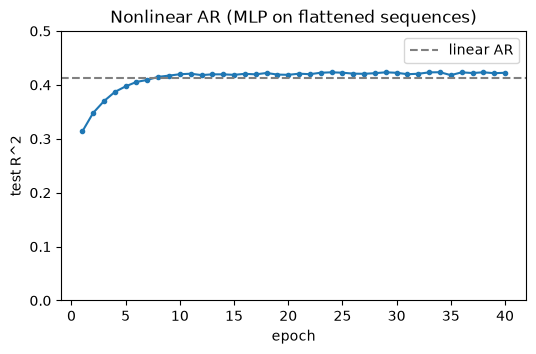

Nonlinear AR (flattened sequences, no day-of-week): test R^2 = 0.4225


In [10]:
# Exercise 11
class FlatMLP(nn.Module):
    def __init__(self, p, hidden=32, dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(p, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

X_rnn_t = torch.tensor(X_rnn, dtype=torch.float32)
Yn_t = torch.tensor(Yn.to_numpy(), dtype=torch.float32)
tr_mask = torch.tensor(train_n.to_numpy())
r2_metric = lambda out, y: r2_score(y.numpy(), out.numpy())

torch.manual_seed(0)
nl_ar = FlatMLP(15)
hist_nl = train_torch(nl_ar, TensorDataset(X_rnn_t[tr_mask], Yn_t[tr_mask]), epochs=40, lr=1e-3,
                      valid=(X_rnn_t[~tr_mask], Yn_t[~tr_mask]), metric=r2_metric)
r2_nl = hist_nl["valid"].iloc[-1]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(hist_nl["epoch"], hist_nl["valid"], marker="o", ms=3)
ax.axhline(r2_flat, color="gray", ls="--", label="linear AR")
ax.set(xlabel="epoch", ylabel="test R^2", title="Nonlinear AR (MLP on flattened sequences)", ylim=(0, 0.5))
ax.legend()
plt.show()
print(f"Nonlinear AR (flattened sequences, no day-of-week): test R^2 = {r2_nl:.4f}")

**Observations / conclusions**

A nonlinear AR model, an MLP with one 32-unit ReLU hidden layer and 50% dropout on the 15 flattened inputs (no day-of-week), reaches **test R² ≈ 0.42**. That is slightly better than the linear AR model (0.413) and about the same as the RNN (≈ 0.41). The gain from nonlinearity is small: next-day volume is mostly a linear function of recent volume, returns and volatility.

---

## Exercise 12 · Applied

**Textbook: printed page 467**

Consider the RNN fit to the NYSE data in Section 10.9.6. Modify the
code to allow inclusion of the variable day_of_week, and fit the RNN.
Compute the test R2.

RNN input with day_of_week: (6046, 5, 8)


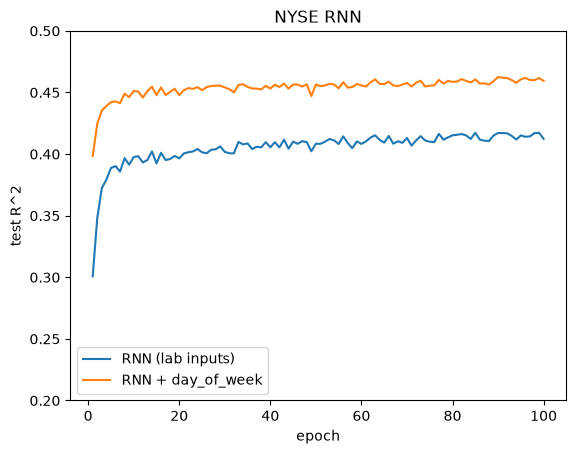

,test R^2
RNN (lab inputs),0.4124
RNN + day_of_week,0.4594
Linear AR + day_of_week,0.4596


In [11]:
# Exercise 12
# Add the (target) day_of_week as five one-hot channels at every time step, so the RNN input becomes (n, 5, 8).
dow = pd.get_dummies(NYSE.loc[Xn.index, "day_of_week"], dtype=float).to_numpy()
X_rnn_dow = np.concatenate([X_rnn, np.repeat(dow[:, None, :], 5, axis=1)], axis=2)
print("RNN input with day_of_week:", X_rnn_dow.shape)

class NYSERNN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.rnn = nn.RNN(n_features, 12, batch_first=True)
        self.dropout = nn.Dropout(0.1)
        self.dense = nn.Linear(12, 1)
    def forward(self, x):
        val, _ = self.rnn(x)
        return self.dense(self.dropout(val[:, -1])).squeeze(-1)

results_12 = {}
for name, arr in [("RNN (lab inputs)", X_rnn), ("RNN + day_of_week", X_rnn_dow)]:
    Xt = torch.tensor(arr, dtype=torch.float32)
    torch.manual_seed(0)
    model = NYSERNN(arr.shape[2])
    hist = train_torch(model, TensorDataset(Xt[tr_mask], Yn_t[tr_mask]), epochs=100, lr=1e-3,
                       valid=(Xt[~tr_mask], Yn_t[~tr_mask]), metric=r2_metric)
    results_12[name] = hist["valid"].iloc[-1]
    plt.plot(hist["epoch"], hist["valid"], label=name)
plt.xlabel("epoch"); plt.ylabel("test R^2"); plt.ylim(0.2, 0.5); plt.legend(); plt.title("NYSE RNN")
plt.show()

# Linear AR with day_of_week for reference
X_day = np.column_stack([X_flat, dow])
r2_lin_day = r2_score(Yn[~train_n], LinearRegression().fit(X_day[train_n], Yn[train_n]).predict(X_day[~train_n]))
results_12["Linear AR + day_of_week"] = r2_lin_day
pd.Series(results_12, name="test R^2").round(4).to_frame()

**Observations / conclusions**

I added the target day's `day_of_week` (5 one-hot channels, repeated at each of the 5 time steps) to the RNN input, giving shape (n, 5, 8).

| model | test R² |
|---|---|
| RNN, lab inputs | 0.412 |
| **RNN + day_of_week** | **0.459** |
| Linear AR + day_of_week | 0.460 |

Day of week clearly helps (+0.05 R²): trading volume has a strong weekly pattern. With it, the RNN matches the linear AR model that has the same information. The RNN gains little beyond what a linear model can capture.

---

## Exercise 13 · Applied

**Textbook: printed page 467**

Repeat the analysis of Lab 10.9.5 on the IMDb data using a similarly
structured neural network. We used 16 hidden units at each of two
hidden layers. Explore the effect of increasing this to 32 and 64 units
per layer, with and without 30% dropout regularization.

train (23000, 10003), validation (2000, 10003), test (25000, 10003)


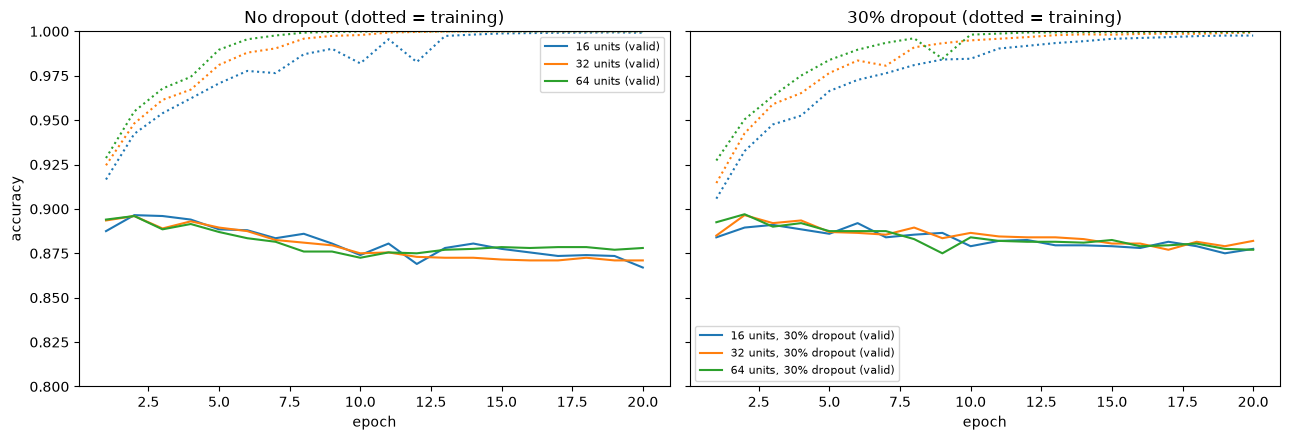

,best valid acc,best epoch,test acc at best epoch,final train acc,final valid acc,test acc (after 20 epochs)
model,,,,,,
16 units,0.8965,2,0.8910,0.9992,0.8670,0.8478
"16 units, 30% dropout",0.8920,6,0.8829,0.9976,0.8775,0.8690
32 units,0.8960,2,0.8887,1.0000,0.8710,0.8584
"32 units, 30% dropout",0.8965,2,0.8879,0.9993,0.8820,0.8682
64 units,0.8960,2,0.8864,1.0000,0.8780,0.8644
"64 units, 30% dropout",0.8970,2,0.8887,0.9996,0.8770,0.8688


In [12]:
# Exercise 13
from ISLP.torch.imdb import load_sparse

((X_tr, Y_tr), (X_va, Y_va), (X_te, Y_te)) = load_sparse(validation=2000, random_state=0, root="data/IMDB")
print(f"train {X_tr.shape}, validation {X_va.shape}, test {X_te.shape}")

class IMDBNet(nn.Module):
    def __init__(self, p, hidden, dropout):
        super().__init__()
        layers = [nn.Linear(p, hidden), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        layers += [nn.Linear(hidden, hidden), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(hidden, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def to_dense(X):
    return torch.tensor(X.toarray(), dtype=torch.float32)

def sparse_accuracy(model, X, y, batch=2000):
    model.eval()
    correct = 0
    with torch.no_grad():
        for start in range(0, X.shape[0], batch):
            out = model(to_dense(X[start:start + batch]))
            correct += ((out > 0).numpy() == y[start:start + batch]).sum()
    return correct / X.shape[0]

def fit_imdb(hidden, dropout, epochs=20, batch_size=512, seed=0):
    torch.manual_seed(seed)
    model = IMDBNet(X_tr.shape[1], hidden, dropout)
    opt = torch.optim.RMSprop(model.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    order_rng = np.random.default_rng(seed)
    y_t = torch.tensor(Y_tr, dtype=torch.float32)
    hist = []
    for epoch in range(epochs):
        model.train()
        perm = order_rng.permutation(X_tr.shape[0])
        for start in range(0, len(perm), batch_size):
            idx = perm[start:start + batch_size]
            opt.zero_grad()
            loss_fn(model(to_dense(X_tr[idx])), y_t[idx]).backward()
            opt.step()
        hist.append({"epoch": epoch + 1, "train": sparse_accuracy(model, X_tr, Y_tr),
                     "valid": sparse_accuracy(model, X_va, Y_va),
                     "test": sparse_accuracy(model, X_te, Y_te)})
    return model, pd.DataFrame(hist)

rows, histories = [], {}
for hidden in [16, 32, 64]:
    for dropout in [0.0, 0.3]:
        model, hist = fit_imdb(hidden, dropout)
        label = f"{hidden} units" + (", 30% dropout" if dropout else "")
        histories[label] = hist
        best = hist.loc[hist["valid"].idxmax()]
        rows.append({"model": label, "best valid acc": best["valid"], "best epoch": int(best["epoch"]),
                     "test acc at best epoch": best["test"],
                     "final train acc": hist["train"].iloc[-1], "final valid acc": hist["valid"].iloc[-1],
                     "test acc (after 20 epochs)": hist["test"].iloc[-1]})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for label, hist in histories.items():
    ax = axes[1] if "dropout" in label else axes[0]
    ax.plot(hist["epoch"], hist["valid"], label=f"{label} (valid)")
    ax.plot(hist["epoch"], hist["train"], ls=":", color=ax.lines[-1].get_color())
axes[0].set(title="No dropout (dotted = training)", xlabel="epoch", ylabel="accuracy", ylim=(0.8, 1.0))
axes[1].set(title="30% dropout (dotted = training)", xlabel="epoch")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("model").round(4)

**Observations / conclusions**

Two-hidden-layer networks on the 10,000-word bag-of-words IMDb features, trained for 20 epochs with RMSprop (lr 0.001, batch 512):

- **All widths overfit quickly.** Validation accuracy peaks at about **89.2–89.7%**, after just 2 epochs for every model except the 16-unit dropout model (epoch 6), while training accuracy then climbs to ~100%. By epoch 20, validation accuracy has fallen to 86.7–88.2%.
- **Width barely matters.** 16, 32 and 64 units all reach about the same best validation accuracy (89.2–89.7%), and test accuracy at that epoch is 88.3–89.1%. Extra units mostly add capacity to memorise.
- **30% dropout slows the overfitting.** After 20 epochs, the dropout models keep 0.4–2 points more test accuracy (86.8–86.9% vs 84.8–86.4%). The gap is largest for the 16-unit model (86.9% vs 84.8%). Dropout does not raise the *peak* accuracy.

Early stopping matters more than width or dropout here. Stopping at the best validation epoch gives about 89% test accuracy for every configuration, in line with the lab's results for this data.